# Day 11 - Temporal Preprocessing Pipeline

## Objective

The objective of Day 11 is to implement a reusable preprocessing pipeline for the timestamped water-quality dataset.
The pipeline includes timestamp validation, duplicate handling, chronological sorting, missing-value imputation,
physical domain quality filtering, chronological 70/15/15 train/val/test splitting, and feature scaling without leakage.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_11_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

processed_path = ROOT / "data" / "processed" / "water_quality_timestamped.csv"
df = pd.read_csv(processed_path)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.sort_values("timestamp").reset_index(drop=True)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (3276, 11)
Columns: ['timestamp', 'ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']


,timestamp,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,2025-01-01 00:00:00,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,2025-01-01 01:00:00,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,2025-01-01 02:00:00,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,2025-01-01 03:00:00,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,2025-01-01 04:00:00,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 1. Timestamp Preprocessing

The timestamp column is converted into a datetime format and records are sorted chronologically.
Invalid timestamps are identified and removed because temporal ordering is required for downstream time-series processing.

In [2]:
print("Invalid timestamps:", df["timestamp"].isna().sum())
df = df.dropna(subset=["timestamp"]).copy()
df = df.sort_values("timestamp").reset_index(drop=True)
print("Shape after timestamp validation:", df.shape)
print("Chronologically sorted:", df["timestamp"].is_monotonic_increasing)

Invalid timestamps: 0
Shape after timestamp validation: (3276, 11)
Chronologically sorted: True


## 2. Duplicate Timestamp Handling

Duplicate timestamps are checked before modeling.
Duplicate records are reduced to one observation per timestamp using the first available record to guarantee deterministic processing.

In [3]:
duplicate_count = df["timestamp"].duplicated().sum()
print("Duplicate timestamps before cleaning:", duplicate_count)
df = df.sort_values("timestamp").drop_duplicates(subset=["timestamp"], keep="first").reset_index(drop=True)
print("Duplicate timestamps after cleaning:", df["timestamp"].duplicated().sum())
print("Shape after duplicate handling:", df.shape)

Duplicate timestamps before cleaning: 0
Duplicate timestamps after cleaning: 0
Shape after duplicate handling: (3276, 11)


## 3. Missing-Value Handling

Missing values are identified for each parameter.
For this temporal dataset, numeric missing values are filled using causal forward filling.

In [4]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Missing values before handling:")
display(df[numeric_columns].isna().sum())
df[numeric_columns] = df[numeric_columns].ffill()
print("Missing values after forward filling:")
display(df[numeric_columns].isna().sum())

Missing values before handling:


ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Missing values after forward filling:


ph                 1
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

## 4. Basic Data-Quality Filtering

Physically impossible negative values are treated as invalid for parameters that cannot logically be negative.
Domain boundary assertions are enforced for pH and binary Potability labels.

In [5]:
non_negative_columns = ["Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes", "Turbidity"]
for column in non_negative_columns:
    if column in df.columns:
        df = df[df[column] >= 0]
if "ph" in df.columns:
    df = df[(df["ph"] >= 0) & (df["ph"] <= 14)]
if "Potability" in df.columns:
    df = df[df["Potability"].isin([0, 1])]
df = df.reset_index(drop=True)
print("Shape after basic quality filtering:", df.shape)

Shape after basic quality filtering: (3275, 11)


## 5. Chronological Train / Validation / Test Split

Random splitting is avoided because it can introduce future information into the training data.
The dataset is divided chronologically: 70% training, 15% validation, and 15% testing.

In [6]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()
print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)
print("\nTrain period:", train_df["timestamp"].min(), "->", train_df["timestamp"].max())
print("Validation period:", val_df["timestamp"].min(), "->", val_df["timestamp"].max())
print("Test period:", test_df["timestamp"].min(), "->", test_df["timestamp"].max())

Train shape: (2292, 11)
Validation shape: (491, 11)
Test shape: (492, 11)

Train period: 2025-01-01 01:00:00 -> 2025-04-06 12:00:00
Validation period: 2025-04-06 13:00:00 -> 2025-04-26 23:00:00
Test period: 2025-04-27 00:00:00 -> 2025-05-17 11:00:00


## 6. Feature Scaling

StandardScaler is fitted only on the training data to prevent information leakage from validation and test observations.
The fitted scaler transforms validation and test partitions.

In [7]:
from sklearn.preprocessing import StandardScaler
feature_columns = [col for col in numeric_columns if col != "Potability"]
scaler = StandardScaler()
train_scaled = train_df.copy()
val_scaled = val_df.copy()
test_scaled = test_df.copy()
train_scaled[feature_columns] = scaler.fit_transform(train_df[feature_columns])
val_scaled[feature_columns] = scaler.transform(val_df[feature_columns])
test_scaled[feature_columns] = scaler.transform(test_df[feature_columns])
print("Scaling completed without leakage.")

Scaling completed without leakage.


## 7. Processed Partition Persistence

The cleaned, scaled chronological partitions are saved to both data/processed/ and outputs/tables/ for downstream modeling.
Preserving partitions ensures full reproducibility.

In [8]:
output_dir = ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
train_scaled.to_csv(output_dir / "train_v1.csv", index=False)
val_scaled.to_csv(output_dir / "validation_v1.csv", index=False)
test_scaled.to_csv(output_dir / "test_v1.csv", index=False)
train_scaled.to_csv(TBL_DIR / "day11_task1_train_v1.csv", index=False)
val_scaled.to_csv(TBL_DIR / "day11_task1_validation_v1.csv", index=False)
test_scaled.to_csv(TBL_DIR / "day11_task1_test_v1.csv", index=False)
print("Processed Dataset V1 partitions saved successfully to:", output_dir.relative_to(ROOT))

Processed Dataset V1 partitions saved successfully to: data\processed


## 8. Chronological Boundary & Distribution Diagnostics

We assert that train partition timestamps end before validation starts, and validation ends before test starts.
Visual timeline and distribution summary tables are generated and serialized.

TRAIN: (2292, 11) 2025-01-01 01:00:00 to 2025-04-06 12:00:00
VALIDATION: (491, 11) 2025-04-06 13:00:00 to 2025-04-26 23:00:00
TEST: (492, 11) 2025-04-27 00:00:00 to 2025-05-17 11:00:00

Chronological checks:
Train ends before validation: True
Validation ends before test: True
Train feature means approximately 0:


ph                 0.0
Hardness          -0.0
Solids             0.0
Chloramines       -0.0
Sulfate           -0.0
Conductivity      -0.0
Organic_carbon     0.0
Trihalomethanes   -0.0
Turbidity         -0.0
dtype: float64

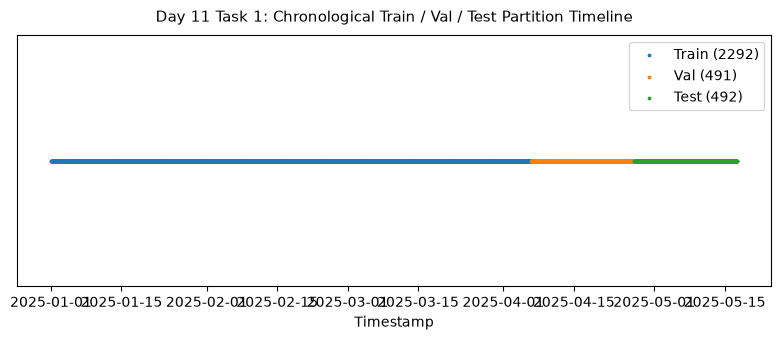

,Partition,Samples,Start,End
0,Train,2292,2025-01-01 01:00:00,2025-04-06 12:00:00
1,Validation,491,2025-04-06 13:00:00,2025-04-26 23:00:00
2,Test,492,2025-04-27 00:00:00,2025-05-17 11:00:00


Saved figure to: Day_Wise_Tasks\Day_11_Task_1\outputs\figures\day11_temporal_split.png
Saved table to: Day_Wise_Tasks\Day_11_Task_1\outputs\tables\day11_preprocessed_summary.csv


In [9]:
print("TRAIN:", train_scaled.shape, train_scaled["timestamp"].min(), "to", train_scaled["timestamp"].max())
print("VALIDATION:", val_scaled.shape, val_scaled["timestamp"].min(), "to", val_scaled["timestamp"].max())
print("TEST:", test_scaled.shape, test_scaled["timestamp"].min(), "to", test_scaled["timestamp"].max())
print("\nChronological checks:")
print("Train ends before validation:", train_scaled["timestamp"].max() <= val_scaled["timestamp"].min())
print("Validation ends before test:", val_scaled["timestamp"].max() <= test_scaled["timestamp"].min())
print("Train feature means approximately 0:")
display(train_scaled[feature_columns].mean().round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(train_scaled["timestamp"], [1]*len(train_scaled), s=3, color="#1f77b4", label=f"Train ({len(train_scaled)})")
ax.scatter(val_scaled["timestamp"], [1]*len(val_scaled), s=3, color="#ff7f0e", label=f"Val ({len(val_scaled)})")
ax.scatter(test_scaled["timestamp"], [1]*len(test_scaled), s=3, color="#2ca02c", label=f"Test ({len(test_scaled)})")
ax.set_yticks([])
ax.set_title("Day 11 Task 1: Chronological Train / Val / Test Partition Timeline", fontsize=11, pad=10)
ax.set_xlabel("Timestamp")
ax.legend(loc="upper right")
plt.tight_layout()

fig_p = FIG_DIR / "day11_temporal_split.png"
fig.savefig(fig_p, dpi=150, bbox_inches="tight")
plt.show()

df_summary = pd.DataFrame([
    {"Partition": "Train", "Samples": len(train_scaled), "Start": str(train_scaled["timestamp"].min()), "End": str(train_scaled["timestamp"].max())},
    {"Partition": "Validation", "Samples": len(val_scaled), "Start": str(val_scaled["timestamp"].min()), "End": str(val_scaled["timestamp"].max())},
    {"Partition": "Test", "Samples": len(test_scaled), "Start": str(test_scaled["timestamp"].min()), "End": str(test_scaled["timestamp"].max())}
])
display(df_summary)
tbl_p = TBL_DIR / "day11_preprocessed_summary.csv"
df_summary.to_csv(tbl_p, index=False)
print("Saved figure to:", fig_p.relative_to(ROOT))
print("Saved table to:", tbl_p.relative_to(ROOT))

# Day 11 - Assumptions and Methodology

## Assumptions

1. The timestamps are synthetic because the supplied dataset does not contain real temporal information.
2. The original raw dataset is preserved and is not modified.
3. The timestamped dataset generated during Day 8 is treated as the input to the temporal preprocessing pipeline.
4. Duplicate timestamps are handled deterministically by retaining the first record.
5. Missing numeric values are initially handled using forward filling.
6. Invalid parameter values are removed using basic domain constraints.
7. Data is split chronologically into 70% training, 15% validation, and 15% testing.
8. Random train/test splitting is avoided to reduce temporal data leakage.
9. Feature scaling is fitted only on the training data.
10. The same fitted scaler is applied to validation and test data.
11. The preprocessing pipeline is designed to be reusable for future anomaly-detection and forecasting experiments.
12. The generated temporal patterns should not be interpreted as actual environmental or sensor behaviour.

## Day 11 Deliverable

The Day 11 preprocessing pipeline produces:

- Cleaned timestamped data
- Chronological train/validation/test datasets
- Scaled numerical features without leakage
- Reproducible preprocessing steps
- Preserved raw and processed datasets